### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)
    os.makedirs(os.path.join(tmpdir, "chirp"))

/flash/ReiterU/tmp/tomo_CPBKQDZZEQUC


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi

sys.path.append("./")
from plot_functions import characterize_neurons, plot_index, plot_cluster_average, plot_clustering

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
database = [
    {
        "name": "20250110_rec2",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec4",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250121_rec8",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250121_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec5",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/ROI_transformed_corrected_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
        {
        "name": "20241224_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20241224_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec7",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec7/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20259117_rec8",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250117_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/ROI_van_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec9",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec6",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec6/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
]

### load data

In [7]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_merged/result_combined_merged.hdf5", mode='r') as store:
    R = store["R"]
    E = store["E"]

Add depth map

In [8]:
for (k, d) in enumerate(database):
    sub_df = R[R["recording"]==k]
    if d["depth_map"] is not None:
        depth_map = pd.read_csv(d["depth_map"])["depth"].to_numpy()
    else:
        depth_map = np.zeros(sub_df.shape[0])
    R.loc[sub_df.index, "depth"] = depth_map

In [9]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,spca_21,spca_22,spca_23,spca_24,spca_25,spca_26,spca_27,spca_28,spca_29,depth
0,0,OGL,0,True,-0.508928,-0.464390,-0.466365,-0.342068,-0.295410,-0.459671,...,3.709491,-4.282827,-0.105844,2.921576,-2.371190,6.794475,1.638139,-1.561589,-2.704803,75.545300
1,0,OGL,1,True,-0.257964,-0.253338,-0.456095,-0.514363,-0.351929,-0.346033,...,-1.933449,1.602021,-1.236076,-1.521483,-0.380997,-4.370857,0.172448,1.170956,2.915614,73.815520
2,0,OGL,2,True,-0.602118,-0.612503,-0.581508,-0.606921,-0.662248,-0.678898,...,-3.903314,-4.688595,2.911292,4.142401,2.702043,13.248385,-2.709772,-9.203449,-3.090206,75.135254
3,0,OGL,3,True,0.563219,0.600015,0.847742,0.828184,0.842527,0.744541,...,-2.478874,0.828057,-1.545227,-1.273875,-0.399481,-8.381687,-0.387511,2.143006,4.293992,71.755010
4,0,OGL,4,True,0.572637,0.440795,0.267777,0.706606,0.556995,0.539196,...,0.599556,-1.176504,1.177105,-0.400154,-0.211736,6.968509,-0.774289,-3.296001,-1.535753,70.591290
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,20,IGL,187,True,0.576814,0.268578,0.004038,0.212486,0.774889,0.519236,...,1.341109,-1.425903,-1.533258,1.292770,0.239178,-1.165633,-0.675126,2.866180,0.216316,0.000000
2995,20,IGL,188,False,0.203239,0.787004,0.771219,0.418283,0.112171,-0.219562,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2996,20,IGL,189,False,0.226999,0.060144,0.330831,0.602990,0.920282,0.464031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2997,20,IGL,190,True,-0.093924,-0.147579,-0.555467,-0.544272,-0.422625,-0.378776,...,-0.621915,10.703491,-2.334290,-0.142033,1.796851,1.115120,0.315398,-7.363258,-0.230249,0.000000


In [10]:
display(E)

y
recording neuron session trial time            
0         0      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
20        191    2       9      18750 -1.157461
                                18800 -2.285858
                                18850 -1.617408
                                18900 -0.432541
                                18950  0.188074

[45148320 rows x 1 columns]

### Show spatial distribution

In [11]:
cluster_ids = R[R["good"]]["cluster"].sort_values().unique()

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C",
    "#2BCE48", "#94FFB5", "#FFCC99", "#9DCC00",
    "#C20088", "#003380", "#FFA405", "#8F7C00", 
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005", "#808080"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

In [12]:
def show_spatial_distribution(db, rec, df, cluster_color_lut, vmin=None, vmax=None, figsize=(1.5, 1.5), figsavename=None):
    template = cv2.imread(db[rec]["template_img"], -1)
    rois = roiread(db[rec]["roifile"])
    rois = sorted(rois, key=lambda x: x.name)
    contours = [r.subpixel_coordinates.astype("int") for r in rois]
    coms = [r.subpixel_coordinates.mean(axis=0) for r in rois]

    img = template.copy().astype("float")
    if vmin is None:
        vmin = np.percentile(img, 1)
    if vmax is None:
        vmax = np.percentile(img, 99)
    img = 255 * (img - vmin) / (vmax - vmin)
    img = np.clip(img, 0, 255).astype("uint8")
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    sub_df = df[df["recording"] == rec]
    for (i, r) in sub_df.iterrows():
        cluster = r["cluster"]
        if cluster > 0:
            c = cluster_color_lut[cluster]
            c = [int(255 * v) for v in c]
            cv2.drawContours(img, contours, contourIdx=r["neuron"], color=c, thickness=-1, lineType=cv2.LINE_AA)

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.axis("off")
    ax.imshow(img)
    plt.tight_layout()
    if figsavename:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

In [ ]:
for j in range(len(database)):
    print(j)
    show_spatial_distribution(database, j, R, color_map, figsavename=os.path.join(tmpdir, f"rec{j:02d}_spatial.pdf"))

### Compute entropy

In [13]:
def get_centroid_cluster_id(db, rec, df, pixel_size_um=0.52):
    rois = roiread(db[rec]["roifile"])
    rois = sorted(rois, key=lambda x: x.name)
    contours = [r.subpixel_coordinates.astype("int") for r in rois]
    coms = [r.subpixel_coordinates.mean(axis=0) for r in rois]

    out = []
    sub_df = df[df["recording"] == rec]
    for (i, r) in sub_df.iterrows():
        out.append({
            "cluster": r["cluster"],
            "com_x": coms[r["neuron"]][0] * pixel_size_um,
            "com_y": coms[r["neuron"]][1] * pixel_size_um
        })
    out = pd.DataFrame(data=out)
    return out

In [14]:
spatial_data = get_centroid_cluster_id(database, 0, R)

In [15]:
spatial_data

,cluster,com_x,com_y
0,8.0,25.496248,33.572498
1,11.0,40.857914,28.014999
2,8.0,32.608330,29.347500
3,3.0,48.888332,22.894999
4,6.0,53.959999,15.626665
...,...,...,...
367,13.0,49.191998,257.425995
368,-1.0,38.861336,249.444000
369,2.0,34.493328,240.610275
370,-1.0,16.753044,234.972168


# Neighbor-type Entropy / Mixing Index

In [31]:
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy
from collections import Counter

def compute_neighbor_entropy_stats(input_df, k=6, n_shuffles=1000, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    # Exclude bad cells
    df = input_df[input_df['cluster'] != -1].reset_index(drop=True)
    positions = df[['com_x', 'com_y']].values
    labels = df['cluster'].values

    # Nearest neighbor search
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(positions)
    _, indices = nn.kneighbors(positions)

    # Observed entropy
    entropies = []
    for i, neighbors in enumerate(indices):
        neighbor_labels = labels[neighbors[1:]] # exclude self
        counts = Counter(neighbor_labels)
        probs = np.array(list(counts.values())) / k
        entropies.append(entropy(probs))
    mean_entropy = np.mean(entropies)

    # Null distribution
    null_entropies = []
    for _ in range(n_shuffles):
        shuffled = np.random.permutation(labels)
        tmp_entropies = []
        for i, neighbors in enumerate(indices):
            neighbor_labels = shuffled[neighbors[1:]]
            counts = Counter(neighbor_labels)
            probs = np.array(list(counts.values())) / k
            tmp_entropies.append(entropy(probs))
        null_entropies.append(np.mean(tmp_entropies))
    null_entropies = np.array(null_entropies)

    # P-value: proportion of null entropies less than or equal to observed
    p_value = np.mean(null_entropies <= mean_entropy)

    return null_entropies, mean_entropy, p_value

dataset: 0 mean entropy: 1.412762243114257 p value: 0.173


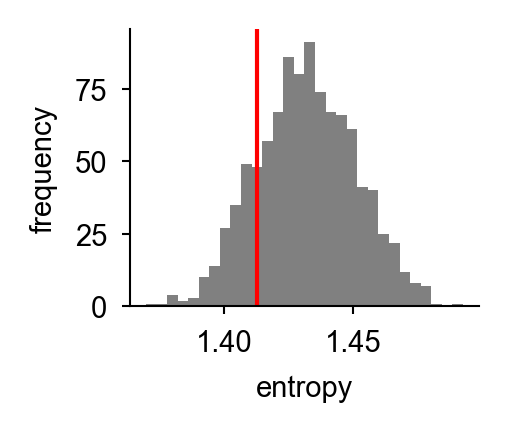

dataset: 1 mean entropy: 1.4340458895035135 p value: 0.296


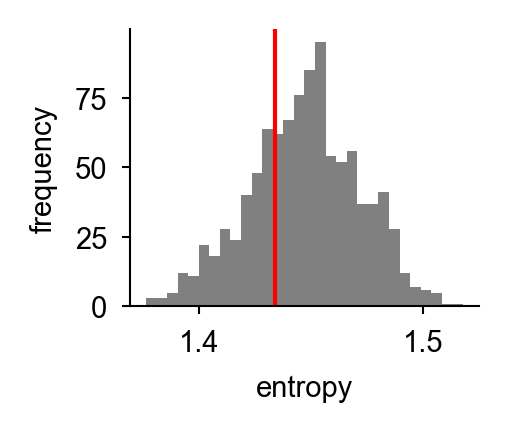

dataset: 7 mean entropy: 1.1110424126741816 p value: 0.108


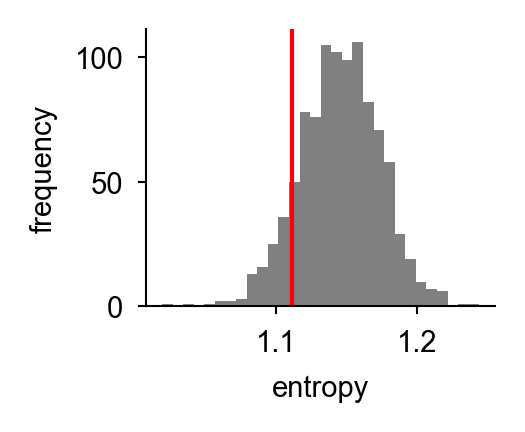

dataset: 19 mean entropy: 1.2995502882773557 p value: 0.786


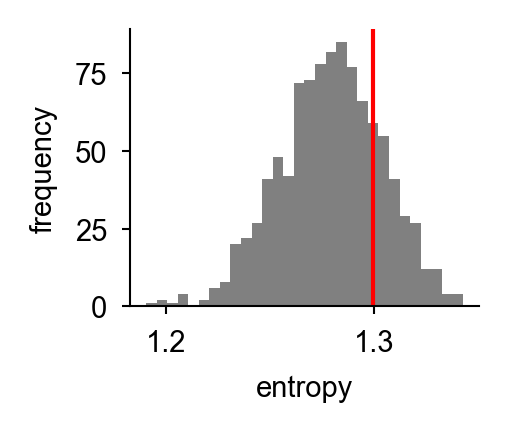

In [32]:
for j in range(len(database)):
    spatial_data = get_centroid_cluster_id(database, j, R)
    # c_counts = spatial_data['cluster'].value_counts()
    # spatial_data = spatial_data[spatial_data['cluster'].isin(c_counts[c_counts >= 5].index)]
    # print(j, spatial_data['cluster'].unique().size, spatial_data.shape[0])
    if spatial_data[spatial_data['cluster']>0].shape[0] < 150:
        continue

    nulls, mean_ent, pval = compute_neighbor_entropy_stats(spatial_data, k=6, n_shuffles=1000)
    print("dataset:", j, "mean entropy:", mean_ent, "p value:", pval)
    
    fig, ax = plt.subplots(figsize=(1.5, 1.2), dpi=300)
    ax.hist(nulls, bins=30, alpha=1, color="gray")
    ax.axvline(mean_ent, color='red', lw=1)
    ax.set_xlabel('entropy')
    ax.set_ylabel('frequency')
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    plt.savefig(os.path.join(tmpdir, f"entropy_rec{j:02d}.pdf"), bbox_inches='tight')
    plt.show()

# Ripley's L function

In [16]:
import pointpats
from scipy.spatial.distance import pdist, squareform

# def ripley_L(points, radii, area=None):
#     """
#     Compute Ripley's L function for a set of 2D points.

#     Parameters:
#     ----------
#     points : ndarray of shape (N, 2)
#         Coordinates of the points (x, y).
#     radii : ndarray
#         Radii at which to evaluate L(r).
#     area : float, optional
#         Total area of the region. If None, estimated from bounding box.

#     Returns:
#     -------
#     Lr : ndarray
#         Ripley's L function values at each radius.
#     """
#     N = len(points)
#     if area is None:
#         # Estimate area from bounding box
#         xmin, ymin = points.min(axis=0)
#         xmax, ymax = points.max(axis=0)
#         area = (xmax - xmin) * (ymax - ymin)

#     intensity = N / area  # point density
#     dists = squareform(pdist(points))  # pairwise distance matrix

#     K_r = []
#     for r in radii:
#         # Count neighbors within distance r, excluding self (diagonal = 0)
#         counts = (dists < r).sum(axis=1) - 1
#         K = np.sum(counts) / (N * intensity)
#         K_r.append(K)

#     K_r = np.array(K_r)
#     # L_r = np.sqrt(K_r / np.pi) - radii
#     L_r = np.sqrt(K_r / np.pi)
#     return L_r

def simulate_random_L(num_points, bounds, radii, n_sim=100):
    xmin, xmax, ymin, ymax = bounds
    area = (xmax - xmin) * (ymax - ymin)

    L_sim = []
    for _ in range(n_sim):
        rand_points = np.column_stack([
            np.random.uniform(xmin, xmax, num_points),
            np.random.uniform(ymin, ymax, num_points)
        ])
        # L_r = ripley_L(rand_points, radii, area=area)
        _, L_r = pointpats.l(rand_points, support=radii)
        L_sim.append(L_r)
    return np.array(L_sim)

0


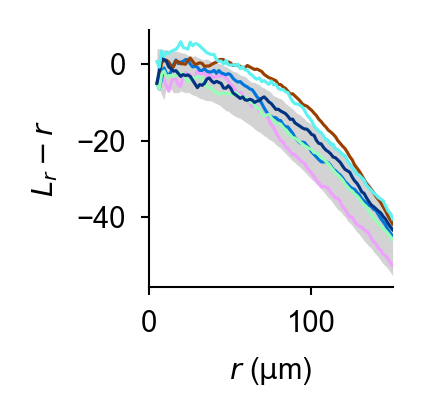

1


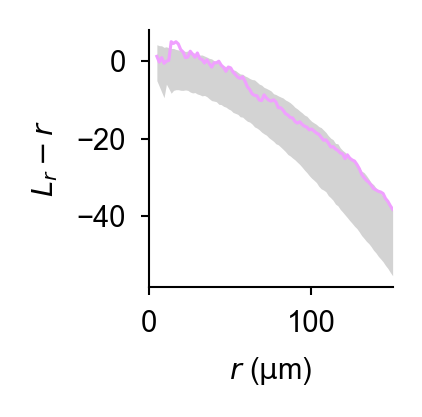

7


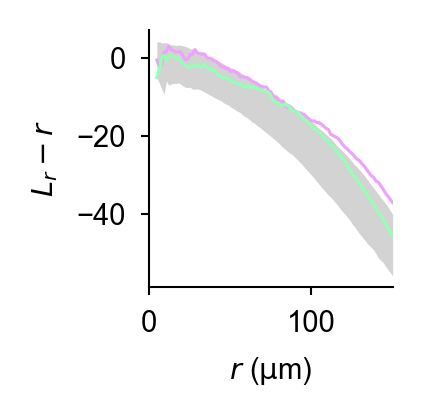

19


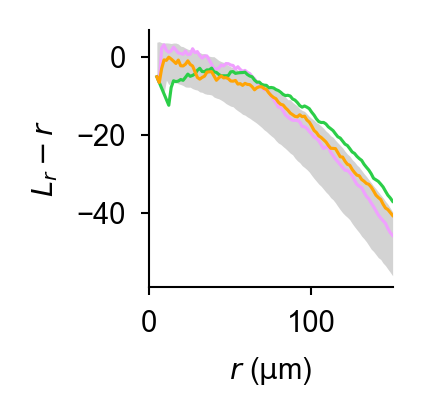

In [27]:
for rec in [0, 1, 7, 19]:
    print(rec)
    spatial_data = get_centroid_cluster_id(database, rec, R)
    spatial_data = spatial_data[spatial_data['cluster'] != -1].reset_index(drop=True)
    c_counts = spatial_data['cluster'].value_counts()
    target_clusters = c_counts[c_counts >= 30].index.to_list()
    
    radii = np.linspace(5, 150, 100)
    result = []
    for cluster_id in target_clusters:
        df_sub = spatial_data[spatial_data['cluster'] == cluster_id]
        points = df_sub[['com_x', 'com_y']].values
        _, L_r = pointpats.l(points, support=radii)
        # L_r = ripley_L(points, radii)
        result.append({
            "cluster": cluster_id,
            "L_r": L_r - radii,
        })
    
    # compute CSR distribution
    points = spatial_data[['com_x', 'com_y']].values
    xmin, ymin = points.min(axis=0)
    xmax, ymax = points.max(axis=0)
    L_null = simulate_random_L(35, (xmin, xmax, ymin, ymax), radii, n_sim=1000) - radii
    
    fig, ax = plt.subplots(figsize=(1.5,1.4), dpi=300)
    
    for r in result:
        ax.plot(radii, r["L_r"], lw=0.75, color=color_map[r["cluster"]], label=r["cluster"], zorder=100+r["cluster"])
    
    ax.fill_between(radii, np.percentile(L_null, 2.5, axis=0), np.percentile(L_null, 97.5, axis=0), lw=0, color="lightgray", alpha=1)
    
    ax.set_xlabel(r"$r$ ($\mathrm{\mu}$m)")
    ax.set_ylabel(r"$L_r - r$")
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.set_xlim(0, 150)
    plt.tight_layout()
    plt.savefig(os.path.join(tmpdir, f"Ripleys_L_{rec}.pdf"), bbox_inches='tight')
    plt.show()

# Distribution of cell types along depth

(792, 1296)


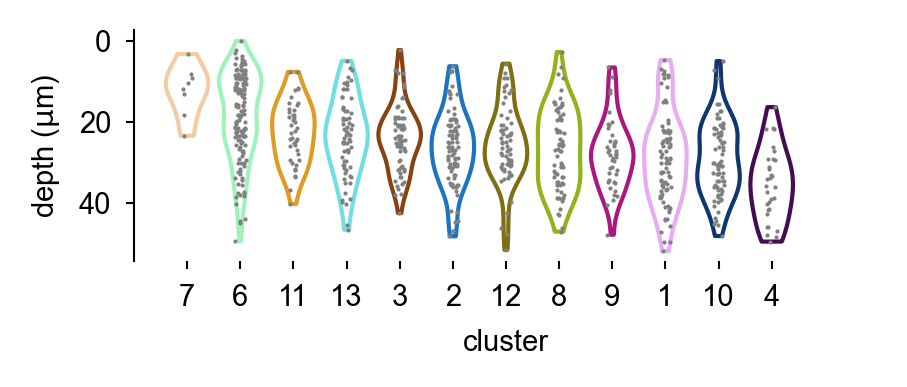

In [28]:
R2 = R[(R["good"]) & (R["recording"].isin([0,1,4,5,6]))]

from matplotlib.collections import PolyCollection

c_counts = R2['cluster'].value_counts()
target_clusters = c_counts[c_counts >= 8].index.to_list()
R2 = R2[R2["cluster"].isin(target_clusters)]
print(R2.shape)

R2["depth_inverted"] = R2["depth"].max() - R2["depth"]
m = R2.groupby("cluster")["depth_inverted"].median()
m.sort_values(inplace=True)
order = m.index

fig, ax = plt.subplots(figsize=(3.2,1.0), dpi=300)
sns.stripplot(R2, x="cluster", y="depth_inverted", color="gray", order=order, size=1, ax=ax)
sns.violinplot(R2, x="cluster", y="depth_inverted", hue="cluster", order=order, inner=None, width=0.8,
               palette=color_map, alpha=1, linewidth=0, cut=0, legend=False, ax=ax)

for collection in ax.collections:
    if isinstance(collection, PolyCollection):
        edge_color = collection.get_facecolor()
        collection.set_facecolor('none')
        collection.set_edgecolor(edge_color)
        collection.set_linewidth(1.0)

for sp in ["top", "right", "bottom"]:
    ax.spines[sp].set_visible(False)
ax.yaxis.set_inverted(True)
ax.set_ylabel(r"depth ($\mathrm{\mu}$m)")
xticks = ax.get_xticks()
ax.set_xticks(xticks)  # explicitly set positions
ax.set_xticklabels([str(int(x)) for x in order])
ax.set_xlim(-1, len(xticks)+1)
plt.savefig(os.path.join(tmpdir, "depth_distribution.pdf"), bbox_inches="tight")
plt.show()

# Statistical tests

In [29]:
from scipy.stats import kruskal
import scikit_posthocs

In [30]:
groups = [group["depth"].values for _, group in R2.groupby("cluster")]
stat, p = kruskal(*groups)
print(p)
print(stat)

2.0682761466599237e-22
129.63004531211377


In [39]:
pc = scikit_posthocs.posthoc_dunn(R2, val_col="depth", group_col="cluster", p_adjust='holm')

In [40]:
pc

,1.0,2.0,3.0,4.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0
1.0,1.000000e+00,1.000000,0.175886,2.047936e-01,8.376441e-11,0.001596,1.000000,1.000000,1.000000e+00,0.048038,1.000000,0.083552
2.0,1.000000e+00,1.000000,1.000000,5.721757e-03,2.813855e-06,0.017525,1.000000,1.000000,1.000000e+00,1.000000,1.000000,1.000000
3.0,1.758860e-01,1.000000,1.000000,8.273809e-05,1.956511e-02,0.139577,1.000000,0.908884,9.661801e-02,1.000000,1.000000,1.000000
4.0,2.047936e-01,0.005722,0.000083,1.000000e+00,2.731638e-13,0.000005,0.017003,0.303267,3.884024e-01,0.000025,0.002738,0.000032
6.0,8.376441e-11,0.000003,0.019565,2.731638e-13,1.000000e+00,1.000000,0.000003,0.000006,4.506711e-11,1.000000,0.000406,0.054066
7.0,1.595879e-03,0.017525,0.139577,5.004077e-06,1.000000e+00,1.000000,0.013067,0.004849,1.041646e-03,0.510991,0.040862,0.191391
8.0,1.000000e+00,1.000000,1.000000,1.700300e-02,2.672344e-06,0.013067,1.000000,1.000000,1.000000e+00,0.790628,1.000000,1.000000
9.0,1.000000e+00,1.000000,0.908884,3.032673e-01,5.888424e-06,0.004849,1.000000,1.000000,1.000000e+00,0.283478,1.000000,0.557365
10.0,1.000000e+00,1.000000,0.096618,3.884024e-01,4.506711e-11,0.001042,1.000000,1.000000,1.000000e+00,0.027373,1.000000,0.045629
11.0,4.803802e-02,1.000000,1.000000,2.534287e-05,1.000000e+00,0.510991,0.790628,0.283478,2.737326e-02,1.000000,1.000000,1.000000


In [67]:
def plot_significance_matrix(pval_df, figsize=(2, 1.2), figsavename=None):
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.colors as mcolors
    from matplotlib.patches import Patch

    N = pval_df.shape[0]

    # Determine significance levels
    significance = np.zeros_like(pval_df.values, dtype=float)  # default: NS = 0
    significance[np.logical_and(pval_df.values < 0.05, pval_df.values >= 0.01)] = 1
    significance[np.logical_and(pval_df.values < 0.01, pval_df.values >= 0.001)] = 2
    significance[pval_df.values < 0.001] = 3

    # Mask lower triangle
    mask = np.triu(np.ones_like(significance, dtype=bool), k=1)

    # Set masked values to -1 so they are colored differently
    display_matrix = significance.copy()
    display_matrix[mask] = -1  # For visualization only
    np.fill_diagonal(display_matrix, -2)

    # Custom colormap with -1 as white
    cmap = mcolors.ListedColormap(['#808080', '#ffffff', '#d3d3d3', '#08306b', '#4292c6', '#c6dbef'])
    # bounds = [-2, -1, 0, 1, 2,3, 2.5, 3]
    # norm = mcolors.BoundaryNorm(bounds, cmap.N)
    bounds = np.arange(-2.5, 4, 1)  # boundaries between colors
    norm = mcolors.BoundaryNorm(bounds, ncolors=6)

    # Plot
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.imshow(display_matrix, cmap=cmap, norm=norm, interpolation="nearest", aspect="equal")
    # ax.imshow(display_matrix, cmap="viridis", vmin=-2, vmax=3, interpolation="nearest", aspect="equal")

    # Ticks and labels
    ax.set_xticks(np.arange(N))
    ax.set_yticks(np.arange(N))
    ax.set_xticklabels(pval_df.columns.astype(int).astype(str))
    ax.set_yticklabels(pval_df.index.astype(int).astype(str))
    ax.tick_params(axis='x', rotation=90)

    # Grid lines
    for i in range(N + 1):
        ax.axhline(i - 0.5, color='w', lw=0.5)
        ax.axvline(i - 0.5, color='w', lw=0.5)

    # # Legend
    # legend_labels = ['NS', 'p < 0.05', 'p < 0.01', 'p < 0.001']
    # legend_colors = [cmap(i + 2) for i in range(4)]  # offset by 2 to skip black and white
    # patches = [Patch(color=legend_colors[i], label=legend_labels[i]) for i in range(4)]
    # ax.legend(
    #     handles=patches,
    #     bbox_to_anchor=(1.05, 1),
    #     loc='upper left',
    #     handlelength=0.5,      # Shorter rectangles
    #     handleheight=0.5,      # Smaller rectangle height
    #     borderpad=0.5,         # Less padding inside legend box
    #     labelspacing=0.2       # Less space between labels
    # )

    for sp in ["top", "right", "bottom", "left"]:
        ax.spines[sp].set_visible(False)
    # ax.set_aspect('equal')
    # plt.tight_layout()
    if figsavename:
        fig.patch.set_facecolor('white')
        plt.savefig(figsavename, bbox_inches="tight")
    plt.show()

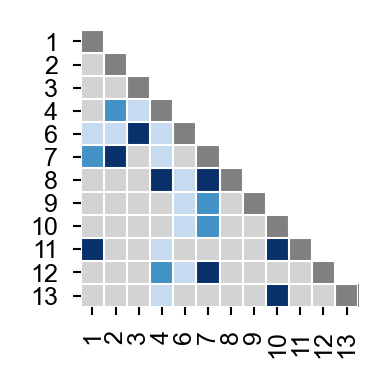

In [68]:
with mpl.rc_context(rc={'font.size': 6, 'axes.titlesize': 6, 'legend.fontsize': 6}):
    plot_significance_matrix(pc, figsize=(1.2, 1.2), figsavename=os.path.join(tmpdir, "depth_pvalues.svg"))

### Save results

In [20]:
with pd.HDFStore(os.path.join(tmpdir, "result_table.hdf5"), mode='w') as store:
    store.put('R', R)

### Copy data to bucket

In [43]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/spatial_analysis"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/spatial_analysis
cp -r /flash/ReiterU/tmp/tomo_FPZDUPJEHAIK/* /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/spatial_analysis


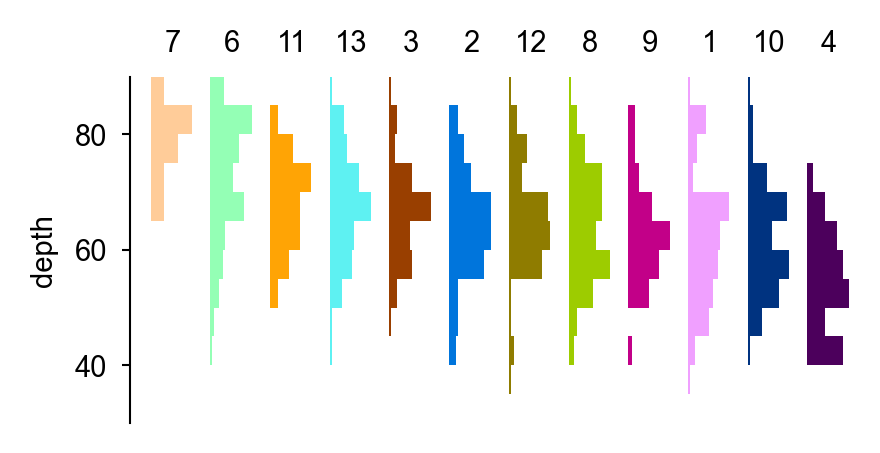

In [72]:

fig = plt.figure(figsize=(3.1,1.5), dpi=300)
gs = fig.add_gridspec(1, m.index.size + 1,
                      width_ratios=[0.1,] + [1,] * m.index.size, wspace=0.4)

range_min, range_max = 30, 90

for (k, c) in enumerate(m.index):
    ax = fig.add_subplot(gs[0, k+1])
    x = R2[R2["cluster"] == c]["depth"].to_numpy()
    count, bin_edges = np.histogram(x, range=[range_min,range_max], bins=12, density=True)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.barh(bin_centers[count>0], count[count>0], height=bin_edges[1]-bin_edges[0], lw=0, alpha=1, color=color_map[c])
    ax.set_ylim([range_min,range_max])
    ax.set_title(f"{int(c)}")
    ax.axis("off")

# scale
ax = fig.add_subplot(gs[0,0])
ax.set_ylim([range_min,range_max])
ax.set_xticks([])
ax.set_ylabel("depth")
for sp in ["top", "right", "bottom"]:
    ax.spines[sp].set_visible(False)

# plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "OGL_depth_distribution.pdf"), bbox_inches='tight')
plt.show()